# Tech Challenge - Fase 1 | Etapa 2: Modelagem e Avaliação
**Pipeline Preditivo de Churn com Modelagem Clássica e API REST** (POSTECH - Machine Learning Engineering)

### Grupo
| **Nome** | **Email** |
|---|---|
| _Derek Seiji Lima Sadakane_ | _rm378493@fiap.com.br_ |
| _Gustavo Eidi Kono Masuno_ | _rm378855@fiap.com.br_ |
| _Jônatas Gomes Alves_ | _rm378082@fiap.com.br_ |
| _Leandro Kersting de Freitas_ | _rm378619@fiap.com.br_ |
| _Matheus de Souza Gonçalves_ | _rm378722@fiap.com.br_ |

<br>

---

## 1. Objetivo desta etapa
Uma operadora de telecomunicações está perdendo clientes em ritmo acelerado e precisa de um modelo que classifique os clientes com **risco de cancelamento (churn)**. Nesta etapa (*Modelagem e Avaliação*), partimos do baseline de Regressão Logística da Etapa 1 e:

1. treinamos um modelo de **Ensemble de Árvores (Random Forest)** com seleção de atributos e tuning de hiperparâmetros;
2. treinamos uma **Rede Neural simples (`MLPClassifier`)**;
3. aplicamos **Validação Cruzada estratificada** a todos os modelos;
4. **comparamos Linear × Árvore × MLP** com as métricas definidas e escolhemos o **modelo campeão**;
5. **registramos os experimentos** e **salvamos o modelo final** (`.joblib`).

### Métricas definidas
| Tipo | Métrica | Justificativa |
|---|---|---|
| Técnica (principal) | **F1-Score** da classe churn | A base é desbalanceada (~27% de churn): a acurácia sozinha seria enganosa. O F1 equilibra *precision* e *recall*. |
| Técnica (secundária) | **AUC-ROC** | Mede a qualidade do ranqueamento de risco, independente do limiar de decisão. |
| Apoio | *Precision*, *Recall* | Dimensionam o custo de alarmes falsos × clientes em risco não identificados. |
| Negócio | Cobertura da cobrança mensal dos clientes que cancelaram (definida no ML Canvas da Etapa 1) | Cada cliente que cancela e não é identificado é receita perdida; o objetivo de negócio é permitir ações de retenção direcionadas. Calculada em `src/evaluate.py`. |

### Entregáveis desta etapa
- **Tabela comparativa de modelos** (seção 8, também salva em `models/02_resultado_treinamento.csv`);
- **Modelo final escolhido e salvo** (`models/02_modelo_campeao.joblib`) + metadados (`models/02_modelo_campeao_metadata.json`);
- **Registro dos experimentos** (`models/02_experimentos_gridsearch.csv` e `models/02_log_experimentos.txt`).

## 2. Configuração do ambiente
Imports, **sementes fixas** (reprodutibilidade) e caminhos centralizados em um único lugar. O notebook deve ser aberto a partir de `notebooks/`: o dataset é lido de `../data/` e os artefatos são salvos em `../models/`. Dependências principais: `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn` e `joblib`.

In [1]:
import json
import platform
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.exceptions import ConvergenceWarning

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
sns.set_theme(style='whitegrid')

# ----- Configuração central (reprodutibilidade) -----
SEED = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
DATASET_NOME = 'IBM_Telco_customer_churn_IBM_dataset.csv'
np.random.seed(SEED)

# ----- Caminhos -----
DATASET_PATH = Path('../data/IBM_Telco_customer_churn_IBM_dataset.csv')

MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f'Dataset carregado com sucesso')

Dataset carregado com sucesso


## 3. Dados: carregamento e decisões de preparação
**Dataset:** *Telco Customer Churn* (IBM), arquivo original `IBM_Telco_customer_churn_IBM_dataset.csv` com **7.043 clientes e 33 colunas**. Antes de modelar, classificamos cada coluna e registramos a decisão tomada:

| Grupo | Colunas | Decisão |
|---|---|---|
| Alvo | `Churn Value` (0/1) | Usada como alvo, nomeada `Churn`. `Churn Label` é só a versão Yes/No dela. |
| **Vazamento de dados (*leakage*)** | `Churn Label`, `Churn Score`, `CLTV`, `Churn Reason` | **Descartadas.** `Churn Label` repete o alvo, `Churn Reason` só existe para quem já cancelou e `Churn Score` é uma pontuação de churn já calculada. O `CLTV` foi descartado por precaução: não sabemos quando nem como essa estimativa foi calculada (ver Etapa 1). Mantê-las poderia gerar métricas artificialmente altas e um modelo inutilizável na API. |
| Constantes | `Count`, `Country`, `State` | Descartadas (um único valor, sem poder preditivo). |
| Identificador / geografia | `CustomerID`, `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude` | Descartadas (o ID não generaliza; a geografia tem altíssima cardinalidade e risco de sobreajuste). |
| Atributos preditivos | demais 19 colunas | Mantidas, com nomes padronizados sem espaços (`tenure`, `MonthlyCharges`, `TotalCharges`...). |

In [2]:
# Padronização dos nomes das colunas (sem espaços)
RENAME_MAP = {
    'CustomerID': 'customerID',
    'Gender': 'gender',
    'Senior Citizen': 'SeniorCitizen',
    'Partner': 'Partner',
    'Dependents': 'Dependents',
    'Tenure Months': 'tenure',
    'Phone Service': 'PhoneService',
    'Multiple Lines': 'MultipleLines',
    'Internet Service': 'InternetService',
    'Online Security': 'OnlineSecurity',
    'Online Backup': 'OnlineBackup',
    'Device Protection': 'DeviceProtection',
    'Tech Support': 'TechSupport',
    'Streaming TV': 'StreamingTV',
    'Streaming Movies': 'StreamingMovies',
    'Contract': 'Contract',
    'Paperless Billing': 'PaperlessBilling',
    'Payment Method': 'PaymentMethod',
    'Monthly Charges': 'MonthlyCharges',
    'Total Charges': 'TotalCharges',
    'Churn Value': 'Churn',
}

COLUNAS_DESCARTADAS = {
    'vazamento (leakage)': ['Churn Label', 'Churn Score', 'CLTV', 'Churn Reason'],
    'constantes': ['Count', 'Country', 'State'],
    'geografia': ['City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude'],
}

TARGET = 'Churn'
NUM_FEATURES = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


def carregar_dados(caminho: Path) -> pd.DataFrame:
    """Lê o .csv original e valida se as colunas esperadas estão presentes."""
    df = pd.read_csv(caminho)
    df.columns = df.columns.str.strip()

    esperadas = set(RENAME_MAP) | {c for cols in COLUNAS_DESCARTADAS.values() for c in cols}
    ausentes = esperadas - set(df.columns)
    if ausentes:
        raise KeyError(f'Colunas esperadas não encontradas no .csv: {sorted(ausentes)}')
    return df


df_raw = carregar_dados(DATASET_PATH)
print(f'Shape bruto: {df_raw.shape}')
df_raw.head(3).T

Shape bruto: (7043, 33)


,0,1,2
CustomerID,3668-QPYBK,9237-HQITU,9305-CDSKC
Count,1,1,1
Country,United States,United States,United States
State,California,California,California
City,Los Angeles,Los Angeles,Los Angeles
Zip Code,90003,90005,90006
Lat Long,"33.964131, -118.272783","34.059281, -118.30742","34.048013, -118.293953"
Latitude,33.964131,34.059281,34.048013
Longitude,-118.272783,-118.30742,-118.293953
Gender,Male,Female,Female


## 4. Limpeza e qualidade dos dados
Principais tratamentos e verificações:

- **`Total Charges`** é lida como texto e tem 11 valores em branco. Todos pertencem a clientes com `tenure = 0` (clientes recentes, ainda não receberam cobrança), portanto o valor correto é **0**. Imputamos 0 em vez de descartar os clientes e **validamos a premissa por código** (`assert`).
- **`Senior Citizen`** é convertida de Yes/No para 0/1.
- Integridade: `CustomerID` é único e `Churn Label` é consistente com `Churn Value` (verificado antes de descartar essas colunas).
- Ao final, garantimos que não restam valores nulos.

In [3]:
def preparar_dados(df_raw: pd.DataFrame) -> pd.DataFrame:
    """Limpeza do dataset: remove colunas inadequadas, padroniza nomes e trata valores ausentes."""
    df = df_raw.copy()

    # 1. Validações de integridade (antes de descartar as colunas usadas nelas)
    assert df['CustomerID'].is_unique, 'CustomerID duplicado'
    assert ((df['Churn Label'] == 'Yes') == (df['Churn Value'] == 1)).all(), 'Churn Label x Churn Value inconsistentes'

    # 2. Remove colunas de vazamento, constantes e geográficas
    descartar = [c for cols in COLUNAS_DESCARTADAS.values() for c in cols]
    df = df.drop(columns=descartar)

    # 3. Padroniza nomes e remove o identificador
    df = df.rename(columns=RENAME_MAP).drop(columns=['customerID'])

    # 4. Tipos: SeniorCitizen Yes/No -> 0/1
    df['SeniorCitizen'] = df['SeniorCitizen'].astype(str).str.strip().map({'No': 0, 'Yes': 1})
    assert df['SeniorCitizen'].notna().all(), 'Valor inesperado em SeniorCitizen'

    # 5. TotalCharges: texto -> número. Brancos pertencem a clientes com tenure == 0
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    sem_cobranca = df['TotalCharges'].isna()
    assert (df.loc[sem_cobranca, 'tenure'] == 0).all(), 'TotalCharges nulo em cliente com tenure > 0'
    df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
    print(f'TotalCharges imputado com 0 em {int(sem_cobranca.sum())} clientes novos (tenure = 0).')

    # 6. Limpa espaços nas categorias (colunas textuais)
    for col in df.columns.difference(NUM_FEATURES + [TARGET]):
        df[col] = df[col].astype(str).str.strip()

    assert df.isna().sum().sum() == 0, 'Ainda existem valores nulos'
    return df


df = preparar_dados(df_raw)

X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

# Listas explícitas de atributos (mais seguro do que inferir por dtype: o pandas 3 usa o dtype 'str', não 'object')
CAT_FEATURES = [c for c in X.columns if c not in NUM_FEATURES]
assert set(NUM_FEATURES) | set(CAT_FEATURES) == set(X.columns)
assert all(not pd.api.types.is_numeric_dtype(X[c]) for c in CAT_FEATURES), 'Categórica com dtype numérico'

print(f'\nShape final: X={X.shape} | numéricas={len(NUM_FEATURES)} | categóricas={len(CAT_FEATURES)}')
print(f'Taxa de churn: {y.mean():.2%} ({y.sum()} de {len(y)} clientes)')

df.head(3).T

TotalCharges imputado com 0 em 11 clientes novos (tenure = 0).

Shape final: X=(7043, 19) | numéricas=4 | categóricas=15
Taxa de churn: 26.54% (1869 de 7043 clientes)


,0,1,2
gender,Male,Female,Female
SeniorCitizen,0,0,0
Partner,No,No,No
Dependents,No,Yes,Yes
tenure,2,2,8
PhoneService,Yes,Yes,Yes
MultipleLines,No,No,Yes
InternetService,DSL,Fiber optic,Fiber optic
OnlineSecurity,Yes,No,No
OnlineBackup,Yes,No,No


A classe positiva (churn) representa cerca de **27%** dos clientes: o problema é desbalanceado. Por isso a acurácia sozinha enganaria (um modelo que sempre prevê "não cancela" acertaria ~73%) e usamos **F1-Score** e **AUC-ROC** como métricas técnicas de comparação, acompanhadas de *precision* e *recall* da classe churn.

## 5. Divisão treino/teste, validação cruzada e Baseline (modelo linear)
Dividimos os dados de forma **estratificada** (preservando a proporção de churn) e definimos um único esquema de validação cruzada (`StratifiedKFold` com semente fixa) que será **reutilizado por todos os modelos**, garantindo comparação justa. O pré-processamento fica dentro de `Pipeline`, evitando vazamento de dados entre treino e validação e *training-serving skew*.

O pré-processador é criado por uma função (*factory*) para que cada pipeline tenha a sua própria instância, sem compartilhar estado ajustado entre modelos.

**Diferenças em relação ao baseline da Etapa 1.** O baseline abaixo não é idêntico ao do notebook 01: aqui ele usa seed 42 (lá, 123), as 19 features (lá, 17, sem `gender` e `SeniorCitizen`) e não usa `class_weight="balanced"` (lá, usa). Por isso os F1 dos dois notebooks **não são comparáveis entre si** (0,606 aqui e 0,642 lá): a divisão e o limiar efetivo são diferentes. Como o Random Forest campeão usa `class_weight="balanced"`, a comparação justa inclui também uma Regressão Logística balanceada na mesma divisão, feita em `src/evaluate.py` e registrada em `models/02_avaliacao_campeao.json`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

print(f'Treino: {X_train.shape} | Teste: {X_test.shape}')
print(f'Churn treino: {y_train.mean():.2%} | Churn teste: {y_test.mean():.2%}')


def criar_preprocessor() -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), NUM_FEATURES),
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT_FEATURES),
        ]
    )


METRICAS_CV = {
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'precision': 'precision',
    'recall': 'recall',
}


def validar_com_cv(modelo, X_tr, y_tr) -> dict:
    """Validação cruzada estratificada com múltiplas métricas (média e desvio-padrão)."""
    res = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=METRICAS_CV, n_jobs=-1)
    saida = {}
    for nome in METRICAS_CV:
        saida[f'cv_{nome}_media'] = res[f'test_{nome}'].mean()
        saida[f'cv_{nome}_std'] = res[f'test_{nome}'].std()
    return saida


def avaliar_no_teste(modelo, X_te, y_te) -> dict:
    """Métricas no conjunto de teste (holdout), usado apenas na avaliação final."""
    pred = modelo.predict(X_te)
    proba = modelo.predict_proba(X_te)[:, 1]
    return {
        'teste_f1': f1_score(y_te, pred),
        'teste_roc_auc': roc_auc_score(y_te, proba),
        'teste_precision': precision_score(y_te, pred),
        'teste_recall': recall_score(y_te, pred),
        'teste_accuracy': accuracy_score(y_te, pred),
    }


# Registro dos experimentos (rastreabilidade: tabela final salva em models/02_resultado_treinamento.csv)
experimentos = {}

# ----- Baseline: Regressão Logística, sem class_weight (diferenças da Etapa 1 na célula acima) -----
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', criar_preprocessor()),
    ('classifier', LogisticRegression(random_state=SEED, max_iter=1000)),
])

metricas_cv = validar_com_cv(baseline_pipeline, X_train, y_train)
baseline_pipeline.fit(X_train, y_train)
experimentos['Regressão Logística (Baseline)'] = {
    'modelo': baseline_pipeline,
    **metricas_cv,
    **avaliar_no_teste(baseline_pipeline, X_test, y_test),
}

print('Baseline treinado com sucesso.')
print(f"CV F1: {metricas_cv['cv_f1_media']:.4f} (±{metricas_cv['cv_f1_std']:.4f}) | "
      f"CV AUC-ROC: {metricas_cv['cv_roc_auc_media']:.4f}")

Treino: (5634, 19) | Teste: (1409, 19)
Churn treino: 26.54% | Churn teste: 26.54%
Baseline treinado com sucesso.
CV F1: 0.6201 (±0.0309) | CV AUC-ROC: 0.8590


## 6. Modelo de Árvores (Ensemble): Random Forest com Seleção de Atributos e Tuning
Reduzir a dimensionalidade removendo atributos redundantes pode melhorar a generalização. Adicionamos `SelectKBest` ao pipeline e usamos o `GridSearchCV` para encontrar a configuração ideal de hiperparâmetros de ambas as etapas (número de atributos selecionados e parâmetros do Random Forest). Como a classe churn é minoritária, `class_weight` também entra na busca.

A seleção de atributos fica **dentro** do pipeline: em cada fold ela é ajustada apenas com os dados de treino do fold, sem olhar a validação.

In [5]:
rf_pipeline = Pipeline(steps=[
    ('preprocessor', criar_preprocessor()),
    ('feature_selection', SelectKBest(score_func=f_classif)),
    ('classifier', RandomForestClassifier(random_state=SEED, n_jobs=-1)),
])

param_grid_rf = {
    'feature_selection__k': [10, 20, 'all'],
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': [None, 'balanced'],
}

grid_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=cv, scoring='f1', n_jobs=-1)
grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_
print(f'Melhores hiperparâmetros (RF): {grid_rf.best_params_}')
print(f'Melhor F1 na validação cruzada (RF): {grid_rf.best_score_:.4f}')

metricas_cv = validar_com_cv(best_rf, X_train, y_train)
experimentos['Random Forest (Tuning + KBest)'] = {
    'modelo': best_rf,
    **metricas_cv,
    **avaliar_no_teste(best_rf, X_test, y_test),
}

Melhores hiperparâmetros (RF): {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200, 'feature_selection__k': 'all'}
Melhor F1 na validação cruzada (RF): 0.6491


Atributos mais importantes segundo o Random Forest ajustado (insumo de explicabilidade para o Model Card da Etapa 4):

Atributos usados pelo modelo: 30 de 30


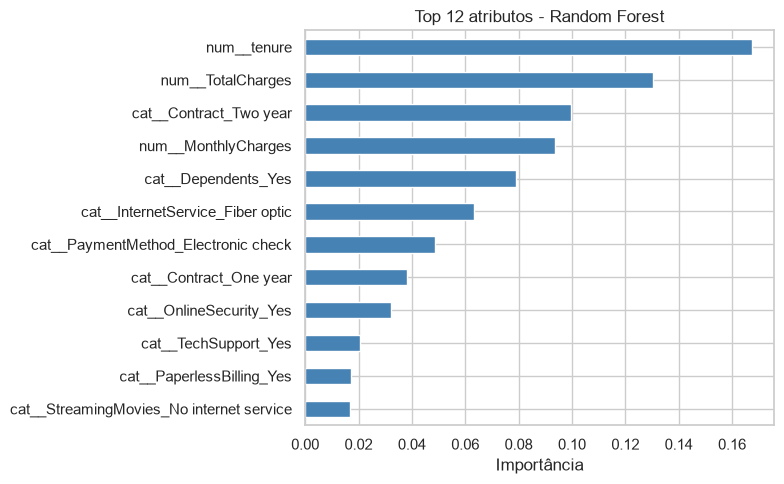

In [6]:
nomes_features = best_rf.named_steps['preprocessor'].get_feature_names_out()
mascara = best_rf.named_steps['feature_selection'].get_support()
importancias = pd.Series(
    best_rf.named_steps['classifier'].feature_importances_,
    index=nomes_features[mascara],
).sort_values(ascending=False)

print(f'Atributos usados pelo modelo: {mascara.sum()} de {len(mascara)}')
fig, ax = plt.subplots(figsize=(8, 5))
importancias.head(12).iloc[::-1].plot.barh(ax=ax, color='steelblue')
ax.set_title('Top 12 atributos - Random Forest')
ax.set_xlabel('Importância')
plt.tight_layout()
plt.show()

## 7. Rede Neural simples (MLPClassifier)
Aplicando o `MLPClassifier` com uma busca em grade pequena (arquitetura e regularização `alpha`), mantendo a rede simples. O `early_stopping` reserva uma fração do treino para parar quando a validação deixa de melhorar. Observação: o `MLPClassifier` não possui `class_weight`, por isso ele é treinado com o desbalanceamento original.

In [7]:
mlp_pipeline = Pipeline(steps=[
    ('preprocessor', criar_preprocessor()),
    ('classifier', MLPClassifier(max_iter=500, early_stopping=True, random_state=SEED)),
])

param_grid_mlp = {
    'classifier__hidden_layer_sizes': [(32,), (64, 32)],
    'classifier__alpha': [1e-4, 1e-2],
}

grid_mlp = GridSearchCV(mlp_pipeline, param_grid_mlp, cv=cv, scoring='f1', n_jobs=-1)
grid_mlp.fit(X_train, y_train)

best_mlp = grid_mlp.best_estimator_
print(f'Melhores hiperparâmetros (MLP): {grid_mlp.best_params_}')
print(f'Melhor F1 na validação cruzada (MLP): {grid_mlp.best_score_:.4f}')

metricas_cv = validar_com_cv(best_mlp, X_train, y_train)
experimentos['Rede Neural (MLP)'] = {
    'modelo': best_mlp,
    **metricas_cv,
    **avaliar_no_teste(best_mlp, X_test, y_test),
}

Melhores hiperparâmetros (MLP): {'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (64, 32)}
Melhor F1 na validação cruzada (MLP): 0.6206


## 8. Tabela comparativa e escolha do modelo campeão
A tabela abaixo é o **entregável de comparação de modelos (Linear × Árvore × MLP)** e reúne, para os três modelos, as métricas de **validação cruzada** (usadas para decidir) e as métricas do **conjunto de teste** (usadas apenas para confirmar).

**Critério de escolha:** maior F1 médio na validação cruzada, com AUC-ROC médio como desempate. Escolher o campeão olhando o conjunto de teste contaminaria a estimativa final de desempenho: o teste deve continuar sendo uma medida independente.

In [8]:
linhas = []
for nome, info in experimentos.items():
    linhas.append({'Modelo': nome, **{k: v for k, v in info.items() if k != 'modelo'}})

df_resultados = (
    pd.DataFrame(linhas)
    .sort_values(by=['cv_f1_media', 'cv_roc_auc_media'], ascending=False)
    .reset_index(drop=True)
)

tabela = pd.DataFrame({
    'Modelo': df_resultados['Modelo'],
    'CV F1 (média ± dp)': df_resultados.apply(lambda r: f"{r['cv_f1_media']:.4f} ± {r['cv_f1_std']:.4f}", axis=1),
    'CV AUC-ROC': df_resultados['cv_roc_auc_media'].round(4),
    'Teste F1': df_resultados['teste_f1'].round(4),
    'Teste AUC-ROC': df_resultados['teste_roc_auc'].round(4),
    'Teste Precision': df_resultados['teste_precision'].round(4),
    'Teste Recall': df_resultados['teste_recall'].round(4),
    'Teste Accuracy': df_resultados['teste_accuracy'].round(4),
})
display(tabela)

,Modelo,CV F1 (média ± dp),CV AUC-ROC,Teste F1,Teste AUC-ROC,Teste Precision,Teste Recall,Teste Accuracy
0,Random Forest (Tuning + KBest),0.6491 ± 0.0163,0.8589,0.6375,0.8519,0.5399,0.7781,0.7651
1,Rede Neural (MLP),0.6206 ± 0.0311,0.8593,0.6141,0.8534,0.6361,0.5936,0.8020
2,Regressão Logística (Baseline),0.6201 ± 0.0309,0.8590,0.6062,0.8490,0.6446,0.5722,0.8027


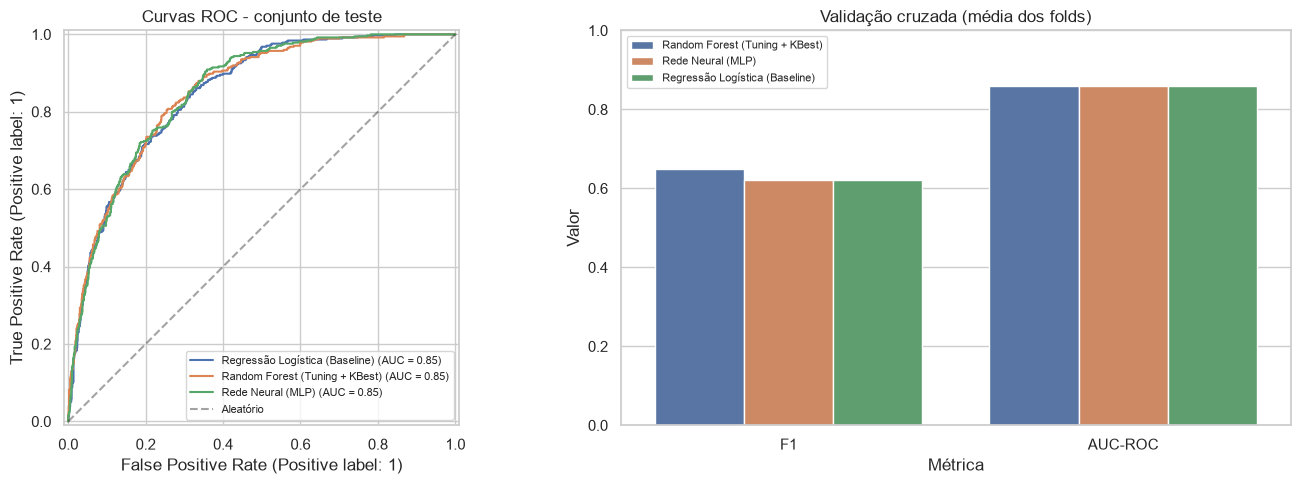

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curvas ROC no conjunto de teste
for nome, info in experimentos.items():
    RocCurveDisplay.from_estimator(info['modelo'], X_test, y_test, name=nome, ax=axes[0])
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Aleatório')
axes[0].set_title('Curvas ROC - conjunto de teste')
axes[0].legend(loc='lower right', fontsize=8)

# Comparação das métricas de validação cruzada (com desvio-padrão)
metricas_plot = df_resultados.melt(
    id_vars='Modelo', value_vars=['cv_f1_media', 'cv_roc_auc_media'],
    var_name='Métrica', value_name='Valor',
)
metricas_plot['Métrica'] = metricas_plot['Métrica'].map({'cv_f1_media': 'F1', 'cv_roc_auc_media': 'AUC-ROC'})
sns.barplot(data=metricas_plot, x='Métrica', y='Valor', hue='Modelo', ax=axes[1])
axes[1].set_title('Validação cruzada (média dos folds)')
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Leitura dos resultados

A célula abaixo resume, a partir da própria tabela, como o campeão se compara ao baseline linear.

**Ressalva:** parte da diferença vem do `class_weight="balanced"`, que o baseline desta tabela não usa. Com os mesmos pesos, na mesma divisão e nos mesmos folds, a Regressão Logística chega a F1 0,640 na CV e 0,618 no teste. O Random Forest continua à frente, mas a vantagem cai de +0,029 para +0,009 na CV (menos de um desvio-padrão entre folds) e, no teste, é de +0,020: mesmo recall, com 29 alarmes falsos a menos. Os números estão em `models/02_avaliacao_campeao.json`.

In [10]:
baseline_nome = 'Regressão Logística (Baseline)'
melhor_modelo_nome = df_resultados.loc[0, 'Modelo']  # df_resultados já está ordenado pelo critério de escolha
c = df_resultados.set_index('Modelo')
campeao, base = c.loc[melhor_modelo_nome], c.loc[baseline_nome]

print(f'Campeão: {melhor_modelo_nome}')
print(f"  F1 (CV)   : {campeao['cv_f1_media']:.4f} vs baseline {base['cv_f1_media']:.4f}  "
      f"(diferença {campeao['cv_f1_media'] - base['cv_f1_media']:+.4f}; desvio-padrão entre folds do campeão: {campeao['cv_f1_std']:.4f})")
print(f"  AUC (CV)  : {campeao['cv_roc_auc_media']:.4f} vs baseline {base['cv_roc_auc_media']:.4f}")
print(f"  F1 (teste): {campeao['teste_f1']:.4f} vs baseline {base['teste_f1']:.4f}")
print(f"  Recall de churn (teste)   : {campeao['teste_recall']:.4f} vs baseline {base['teste_recall']:.4f}")
print(f"  Precision de churn (teste): {campeao['teste_precision']:.4f} vs baseline {base['teste_precision']:.4f}")
print('\nObservação: quando as diferenças de AUC-ROC entre modelos são menores que o desvio-padrão entre folds, '
      'os modelos têm capacidade de ranqueamento equivalente e a escolha se apoia no F1 e no perfil de erros.')

Campeão: Random Forest (Tuning + KBest)
  F1 (CV)   : 0.6491 vs baseline 0.6201  (diferença +0.0290; desvio-padrão entre folds do campeão: 0.0163)
  AUC (CV)  : 0.8589 vs baseline 0.8590
  F1 (teste): 0.6375 vs baseline 0.6062
  Recall de churn (teste)   : 0.7781 vs baseline 0.5722
  Precision de churn (teste): 0.5399 vs baseline 0.6446

Observação: quando as diferenças de AUC-ROC entre modelos são menores que o desvio-padrão entre folds, os modelos têm capacidade de ranqueamento equivalente e a escolha se apoia no F1 e no perfil de erros.


## 9. Avaliação detalhada do modelo campeão
Relatório de classificação e matriz de confusão do modelo escolhido no conjunto de teste. Essas informações alimentam o Model Card da Etapa 4 (performance e limitações).

O modelo escolhido como campeão foi: Random Forest (Tuning + KBest)

               precision    recall  f1-score   support

Permanece (0)       0.90      0.76      0.83      1035
    Churn (1)       0.54      0.78      0.64       374

     accuracy                           0.77      1409
    macro avg       0.72      0.77      0.73      1409
 weighted avg       0.81      0.77      0.78      1409



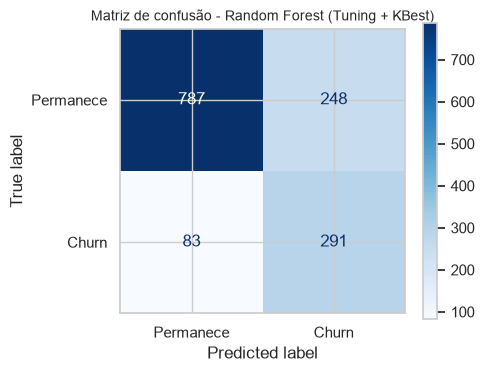

In [11]:
melhor_modelo_nome = df_resultados.loc[0, 'Modelo']
modelo_campeao = experimentos[melhor_modelo_nome]['modelo']
print(f'O modelo escolhido como campeão foi: {melhor_modelo_nome}\n')

y_pred_campeao = modelo_campeao.predict(X_test)
print(classification_report(y_test, y_pred_campeao, target_names=['Permanece (0)', 'Churn (1)']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_campeao, display_labels=['Permanece', 'Churn'], cmap='Blues', ax=ax
)
ax.set_title(f'Matriz de confusão - {melhor_modelo_nome}', fontsize=10)
plt.tight_layout()
plt.show()

## 10. Exportação do modelo final e registro dos experimentos
O melhor pipeline completo (incluindo o pré-processamento validado) é serializado em `models/`. Este objeto contém todos os mapeamentos numéricos e dummies necessários para previsões na API. Salvamos também:

- `02_modelo_campeao_metadata.json`: versões das bibliotecas, semente, atributos de entrada esperados, colunas descartadas e métricas (rastreabilidade e insumo para o contrato da API e para o Model Card);
- `02_resultado_treinamento.csv`: tabela comparativa final dos modelos;
- `02_experimentos_gridsearch.csv`: **registro de todas as combinações de hiperparâmetros testadas** (Random Forest e MLP), com média e desvio-padrão do F1 na validação cruzada;
- `02_log_experimentos.txt`: log em texto com configuração, melhores hiperparâmetros e métricas de cada experimento.

Por fim, recarregamos o arquivo e confirmamos que as previsões são idênticas (*round-trip*), como teste rápido de integridade.

In [12]:
caminho_modelo = MODELS_DIR / '02_modelo_campeao.joblib'
caminho_meta = MODELS_DIR / '02_modelo_campeao_metadata.json'
caminho_resultados = MODELS_DIR / '02_resultado_treinamento.csv'
caminho_grid = MODELS_DIR / '02_experimentos_gridsearch.csv'
caminho_log = MODELS_DIR / '02_log_experimentos.txt'

# 1. Modelo
joblib.dump(modelo_campeao, caminho_modelo)

# 2. Tabela comparativa dos experimentos
df_resultados.to_csv(caminho_resultados, index=False)

# 3. Registro dos experimentos: todas as combinações do GridSearchCV
registro = []
for nome_modelo, grid in [('Random Forest', grid_rf), ('MLP', grid_mlp)]:
    cvr = pd.DataFrame(grid.cv_results_)
    cvr.insert(0, 'modelo', nome_modelo)
    registro.append(cvr[['modelo', 'params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
                    .rename(columns={'mean_test_score': 'f1_cv_media', 'std_test_score': 'f1_cv_std', 'rank_test_score': 'ranking'}))
df_registro = pd.concat(registro, ignore_index=True)
df_registro['params'] = df_registro['params'].astype(str)
df_registro.to_csv(caminho_grid, index=False)

with open(caminho_log, 'w', encoding='utf-8') as f:
    f.write(f"Log de experimentos - Etapa 2 ({datetime.now().isoformat(timespec='seconds')})\n")
    f.write(f'Seed={SEED} | CV={CV_FOLDS} folds estratificados | Teste={TEST_SIZE:.0%} | Dataset={DATASET_PATH.name}\n\n')
    for nome_exp, info in experimentos.items():
        f.write(f'[{nome_exp}]\n')
        for k, v in info.items():
            if k != 'modelo':
                f.write(f'  {k}: {v:.4f}\n')
        f.write('\n')
    f.write(f'Melhores hiperparametros RF : {grid_rf.best_params_}\n')
    f.write(f'Melhores hiperparametros MLP: {grid_mlp.best_params_}\n')
    f.write(f'Campeao: {melhor_modelo_nome}\n')

# 4. Metadados
campeao_info = {k: float(v) for k, v in experimentos[melhor_modelo_nome].items() if k != 'modelo'}
metadata = {
    'modelo': melhor_modelo_nome,
    'criado_em': datetime.now().isoformat(timespec='seconds'),
    'criterio_de_escolha': 'maior F1 médio na validação cruzada (desempate: AUC-ROC)',
    'seed': SEED,
    'cv_folds': CV_FOLDS,
    'test_size': TEST_SIZE,
    'dataset': DATASET_PATH.name,
    'n_linhas': int(len(df)),
    'taxa_churn': float(y.mean()),
    'versoes': {
        'python': platform.python_version(),
        'scikit-learn': sklearn.__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__,
    },
    'features_numericas': NUM_FEATURES,
    'features_categoricas': {c: sorted(X[c].unique().tolist()) for c in CAT_FEATURES},
    'colunas_descartadas': COLUNAS_DESCARTADAS,
    'metricas': campeao_info,
}
caminho_meta.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')

for caminho in (caminho_modelo, caminho_meta, caminho_resultados, caminho_grid, caminho_log):
    print(f'  - {caminho.name} ({caminho.stat().st_size / 1024:.1f} KB)')

# 5. Teste de integridade (round-trip) com um cliente do conjunto de teste
modelo_recarregado = joblib.load(caminho_modelo)
exemplo = X_test.iloc[[0]]
proba_original = modelo_campeao.predict_proba(exemplo)[0, 1]
proba_recarregado = modelo_recarregado.predict_proba(exemplo)[0, 1]
assert np.isclose(proba_original, proba_recarregado), 'Previsões divergem após recarregar o modelo'

print(f'\nRound-trip OK. Probabilidade de churn do cliente de exemplo: {proba_recarregado:.4f}')
print('\nReferência para schema de /predict:')
print(json.dumps(exemplo.iloc[0].to_dict(), indent=2, default=int, ensure_ascii=False))

  - 02_modelo_campeao.joblib (10409.9 KB)
  - 02_modelo_campeao_metadata.json (2.7 KB)
  - 02_resultado_treinamento.csv (1.0 KB)
  - 02_experimentos_gridsearch.csv (16.3 KB)
  - 02_log_experimentos.txt (1.6 KB)

Round-trip OK. Probabilidade de churn do cliente de exemplo: 0.0560

Referência para schema de /predict:
{
  "gender": "Male",
  "SeniorCitizen": 0,
  "Partner": "Yes",
  "Dependents": "No",
  "tenure": 72,
  "PhoneService": "Yes",
  "MultipleLines": "Yes",
  "InternetService": "Fiber optic",
  "OnlineSecurity": "Yes",
  "OnlineBackup": "Yes",
  "DeviceProtection": "Yes",
  "TechSupport": "Yes",
  "StreamingTV": "Yes",
  "StreamingMovies": "Yes",
  "Contract": "Two year",
  "PaperlessBilling": "Yes",
  "PaymentMethod": "Credit card (automatic)",
  "MonthlyCharges": 114.05,
  "TotalCharges": 8468.2
}


### Avaliação complementar

Como o modelo acabou de ser salvo, atualizamos também `models/02_avaliacao_campeao.json`, com a métrica de negócio, o desempenho por subgrupo, a diferença entre treino e teste e a comparação com a Regressão Logística balanceada. O cálculo fica em `src/evaluate.py`, para ser o mesmo usado na linha de comando.


In [13]:
import sys

sys.path.insert(0, '..')  # o notebook é aberto a partir de notebooks/
from src.evaluate import salvar_avaliacao

salvar_avaliacao()
print('Avaliação atualizada: 02_avaliacao_campeao.json')


Avaliação atualizada: 02_avaliacao_campeao.json
